# CS 521 HW4, Problem 3: PPO on CartPole

Open this notebook in Google Colab. The CPU runtime is sufficient: a GPU does not make this notebook faster.

The notebook has a complete implementation of PPO for the CartPole-v1 environment.
In part (a) of Problem 3, you run it and examine two of its parts.
In Bonus Research Question 2, you change the algorithm to improve learning.
Do not change the environment, the training budget (`total_steps`) or the evaluation.

**Environment.** CartPole-v1 gives a reward of +1 for each step. An episode ends when the pole falls
(*termination*) or after 500 steps (*truncation*, a time limit). Thus the maximum return is 500.

In [3]:
# !pip install gymnasium   # Colab has gymnasium. Remove the comment if the import fails.
import copy
import time

import gymnasium as gym
import numpy as np
import torch
import torch.nn as nn
from torch.distributions import Categorical

torch.set_num_threads(1)

CONFIG = dict(
    total_steps=200_000,   # training budget (environment steps). Do not change.
    num_envs=4,            # parallel environments
    num_steps=128,         # steps per environment for each rollout
    lr=2.5e-4,
    anneal_lr=True,        # decrease the learning rate linearly to 0
    gamma=0.99,
    gae_lambda=0.95,
    num_minibatches=4,
    update_epochs=4,
    clip_coef=0.2,
    ent_coef=0.01,
    vf_coef=0.5,
    max_grad_norm=0.5,
    norm_adv=True,         # normalize the advantages in each minibatch
)
SEEDS = [0, 1, 2, 3, 4]

# Environments

`Envs` runs `num_envs` copies of CartPole. When an episode ends, `step` resets that copy automatically.
For each copy, `step` returns:

* `obs`: the next observation. If the episode ended, this is the first observation of the new episode.
* `reward`, `terminated`, `truncated`.
* `final_obs`: the last observation of the episode that ended (`None` if the episode did not end).

`step` also records the return of each finished episode in `self.episodes` as `(global_step, return)`.

In [4]:
class Envs:
    def __init__(self, n, seed):
        self.envs = [gym.make("CartPole-v1") for _ in range(n)]
        self.obs = np.stack([e.reset(seed=seed + i)[0] for i, e in enumerate(self.envs)])
        for i, e in enumerate(self.envs):
            e.action_space.seed(seed + i)
        self.ep_return = np.zeros(n)
        self.global_step = 0
        self.episodes = []

    def step(self, actions):
        rewards, terms, truncs, final_obs = [], [], [], []
        for i, (e, a) in enumerate(zip(self.envs, actions)):
            o, r, term, trunc, _ = e.step(int(a))
            self.ep_return[i] += r
            fo = None
            if term or trunc:
                fo = o
                self.episodes.append((self.global_step + i + 1, self.ep_return[i]))
                self.ep_return[i] = 0
                o, _ = e.reset()
            self.obs[i] = o
            rewards.append(r); terms.append(term); truncs.append(trunc); final_obs.append(fo)
        self.global_step += len(self.envs)
        return self.obs.copy(), np.array(rewards), np.array(terms), np.array(truncs), final_obs

# Agent

The agent has two separate networks with 2 hidden layers of 64 neurons: the actor (policy) and the critic (value).

In [5]:
def layer_init(layer, std=np.sqrt(2), bias=0.0):
    nn.init.orthogonal_(layer.weight, std)
    nn.init.constant_(layer.bias, bias)
    return layer


class Agent(nn.Module):
    def __init__(self, obs_dim=4, n_actions=2):
        super().__init__()
        self.critic = nn.Sequential(
            layer_init(nn.Linear(obs_dim, 64)), nn.Tanh(),
            layer_init(nn.Linear(64, 64)), nn.Tanh(),
            layer_init(nn.Linear(64, 1), std=1.0))
        self.actor = nn.Sequential(
            layer_init(nn.Linear(obs_dim, 64)), nn.Tanh(),
            layer_init(nn.Linear(64, 64)), nn.Tanh(),
            layer_init(nn.Linear(64, n_actions), std=0.01))

    def get_value(self, x):
        return self.critic(x).squeeze(-1)

    def get_action_and_value(self, x, action=None):
        dist = Categorical(logits=self.actor(x))
        if action is None:
            action = dist.sample()
        return action, dist.log_prob(action), dist.entropy(), self.get_value(x)

# PPO

`compute_gae` calculates the advantages with generalized advantage estimation (GAE).
`ppo_update` does `update_epochs` passes over the rollout with the clipped surrogate objective.
`train_ppo(seed, cfg)` trains one agent and returns the agent and the list of `(global_step, return)` of the
training episodes.

In [6]:
def compute_gae(rewards, values, dones, next_value, next_done, gamma, lam):
    # rewards, values, dones: (num_steps, num_envs). dones[t] = 1 if the episode ended at step t - 1,
    # thus obs[t] is the first observation of a new episode.
    T = len(rewards)
    adv = torch.zeros_like(rewards)
    last = 0
    for t in reversed(range(T)):
        not_done = 1.0 - (next_done if t == T - 1 else dones[t + 1])
        nv = next_value if t == T - 1 else values[t + 1]
        delta = rewards[t] + gamma * nv * not_done - values[t]
        last = delta + gamma * lam * not_done * last
        adv[t] = last
    return adv, adv + values


def ppo_update(agent, opt, b, cfg):
    n = len(b["obs"])
    mb_size = n // cfg["num_minibatches"]
    stats = []
    for _ in range(cfg["update_epochs"]):
        idx = torch.randperm(n)
        for start in range(0, n, mb_size):
            mb = idx[start:start + mb_size]
            _, logp, ent, v = agent.get_action_and_value(b["obs"][mb], b["actions"][mb])
            ratio = (logp - b["logp"][mb]).exp()
            adv = b["adv"][mb]
            if cfg["norm_adv"]:
                adv = (adv - adv.mean()) / (adv.std() + 1e-8)
            pg_loss = torch.max(-adv * ratio,
                                -adv * ratio.clamp(1 - cfg["clip_coef"], 1 + cfg["clip_coef"])).mean()
            v_loss = 0.5 * ((v - b["returns"][mb]) ** 2).mean()
            loss = pg_loss - cfg["ent_coef"] * ent.mean() + cfg["vf_coef"] * v_loss
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(agent.parameters(), cfg["max_grad_norm"])
            opt.step()
            stats.append(((ratio - 1).abs() > cfg["clip_coef"]).float().mean().item())
    return {"clip_frac": float(np.mean(stats))}


def train_ppo(seed, cfg=None, verbose=False):
    cfg = {**CONFIG, **(cfg or {})}
    torch.manual_seed(seed)
    np.random.seed(seed)
    envs = Envs(cfg["num_envs"], seed)
    agent = Agent()
    opt = torch.optim.Adam(agent.parameters(), lr=cfg["lr"], eps=1e-5)
    N, T = cfg["num_envs"], cfg["num_steps"]
    n_updates = cfg["total_steps"] // (N * T)
    obs = torch.zeros(T, N, 4); actions = torch.zeros(T, N, dtype=torch.long)
    logps = torch.zeros(T, N); rewards = torch.zeros(T, N); dones = torch.zeros(T, N); values = torch.zeros(T, N)
    next_obs = torch.tensor(envs.obs, dtype=torch.float32)
    next_done = torch.zeros(N)
    start = time.time()
    for update in range(n_updates):
        if cfg["anneal_lr"]:
            opt.param_groups[0]["lr"] = cfg["lr"] * (1 - update / n_updates)
        for t in range(T):
            obs[t], dones[t] = next_obs, next_done
            with torch.no_grad():
                a, logp, _, v = agent.get_action_and_value(next_obs)
            actions[t], logps[t], values[t] = a, logp, v
            o, r, term, trunc, _ = envs.step(a.numpy())
            rewards[t] = torch.tensor(r, dtype=torch.float32)
            next_obs = torch.tensor(o, dtype=torch.float32)
            next_done = torch.tensor(term | trunc, dtype=torch.float32)
        with torch.no_grad():
            adv, returns = compute_gae(rewards, values, dones, agent.get_value(next_obs), next_done,
                                       cfg["gamma"], cfg["gae_lambda"])
        b = {"obs": obs.reshape(-1, 4), "actions": actions.reshape(-1), "logp": logps.reshape(-1),
             "adv": adv.reshape(-1), "returns": returns.reshape(-1)}
        stats = ppo_update(agent, opt, b, cfg)
        if verbose and (update + 1) % 20 == 0:
            recent = [r for _, r in envs.episodes[-10:]]
            print(f"step {envs.global_step:6d}  mean return (last 10) {np.mean(recent):6.1f}  "
                  f"clip frac {stats['clip_frac']:.3f}")
    return agent, envs.episodes, time.time() - start

# Evaluation

`evaluate_policy` runs the greedy policy (the action with the highest probability) for 20 episodes with fixed seeds.
`summarize(runs)` gives these metrics for a list of runs (one run for each seed):

* `auc`: the mean of the learning curve over the training budget. The learning curve is the mean return of the last
  10 training episodes, at 100 equally spaced steps. A higher value means faster learning.
* `steps_to_475`: the first step where the mean return of the last 10 training episodes is at least 475.
  If a run does not get there, we use `total_steps`.
* `final`: the return of the greedy policy at the end of training.

`plot_curves` plots the mean learning curve over the seeds. Use these functions for all the numbers in your report.

In [7]:
@torch.no_grad()
def evaluate_policy(agent, episodes=20, seed=10_000):
    env = gym.make("CartPole-v1")
    total = 0.0
    for k in range(episodes):
        o, _ = env.reset(seed=seed + k)
        done = False
        while not done:
            a = agent.actor(torch.tensor(o, dtype=torch.float32)).argmax().item()
            o, r, term, trunc, _ = env.step(a)
            total += r
            done = term or trunc
    return total / episodes


def learning_curve(episodes, total_steps=CONFIG["total_steps"], points=100, window=10):
    steps = np.array([s for s, _ in episodes])
    rets = np.array([r for _, r in episodes])
    grid = np.linspace(total_steps / points, total_steps, points)
    curve = []
    for g in grid:
        r = rets[steps <= g][-window:]
        curve.append(r.mean() if len(r) else 0.0)
    return grid, np.array(curve)


def steps_to(episodes, target=475, window=10, total_steps=CONFIG["total_steps"]):
    rets = [r for _, r in episodes]
    for k in range(window, len(episodes) + 1):
        if np.mean(rets[k - window:k]) >= target:
            return episodes[k - 1][0]
    return total_steps


def run_seeds(cfg=None, seeds=SEEDS, train_fn=None, verbose=True):
    train_fn = train_fn or train_ppo
    runs = []
    for s in seeds:
        agent, episodes, sec = train_fn(s, cfg)
        runs.append({"seed": s, "episodes": episodes, "time": sec, "final": evaluate_policy(agent)})
        if verbose:
            print(f"seed {s}: auc {learning_curve(episodes)[1].mean():6.1f}  steps_to_475 {steps_to(episodes):6d}  "
                  f"final {runs[-1]['final']:6.1f}  time {sec:5.1f} s")
    return runs


def summarize(runs, name=""):
    auc = [learning_curve(r["episodes"])[1].mean() for r in runs]
    st = [steps_to(r["episodes"]) for r in runs]
    fin = [r["final"] for r in runs]
    res = {"name": name, "auc": np.mean(auc), "auc_std": np.std(auc), "steps_to_475": np.mean(st),
           "solved": sum(s < CONFIG["total_steps"] for s in st), "final": np.mean(fin),
           "final_std": np.std(fin), "time": np.mean([r["time"] for r in runs])}
    print(f"{name:<24} auc {res['auc']:6.1f} +- {res['auc_std']:5.1f}  steps_to_475 {res['steps_to_475']:8.0f} "
          f"({res['solved']}/{len(runs)} runs)  final {res['final']:6.1f} +- {res['final_std']:5.1f}  "
          f"time {res['time']:5.1f} s")
    return res


def plot_curves(named_runs):
    import matplotlib.pyplot as plt
    for name, runs in named_runs.items():
        curves = np.stack([learning_curve(r["episodes"])[1] for r in runs])
        grid = learning_curve(runs[0]["episodes"])[0]
        m, s = curves.mean(0), curves.std(0)
        plt.plot(grid, m, label=name)
        plt.fill_between(grid, m - s, m + s, alpha=0.2)
    plt.xlabel("environment steps"); plt.ylabel("mean return (last 10 episodes)"); plt.legend(); plt.show()

# (a) Run PPO

Train PPO with the default configuration for the 5 seeds. Then train two changed versions:

* Without clipping: `{"clip_coef": 1e9}`.
* Without GAE (Monte Carlo advantages): `{"gae_lambda": 1.0}`.

seed 0: auc  377.2  steps_to_475  69959  final  500.0  time  42.4 s
seed 1: auc  261.4  steps_to_475  67270  final  461.2  time  41.6 s
seed 2: auc  340.3  steps_to_475  75763  final  435.3  time  41.8 s
seed 3: auc  340.7  steps_to_475 123166  final  500.0  time  41.9 s
seed 4: auc  351.0  steps_to_475 101947  final  499.4  time  41.4 s
seed 0: auc  339.6  steps_to_475  62963  final  500.0  time  42.5 s
seed 1: auc  379.0  steps_to_475  86758  final  500.0  time  42.5 s
seed 2: auc  320.9  steps_to_475 104968  final  500.0  time  42.1 s
seed 3: auc  299.4  steps_to_475 123017  final  309.1  time  42.1 s
seed 4: auc  262.7  steps_to_475  45364  final  489.1  time  42.6 s
seed 0: auc  333.9  steps_to_475 139630  final  500.0  time  42.0 s
seed 1: auc  307.0  steps_to_475 199417  final  477.1  time  42.8 s
seed 2: auc  343.3  steps_to_475 128142  final  500.0  time  43.9 s
seed 3: auc  328.7  steps_to_475 107732  final  500.0  time  43.3 s
seed 4: auc  372.6  steps_to_475  73914  final  

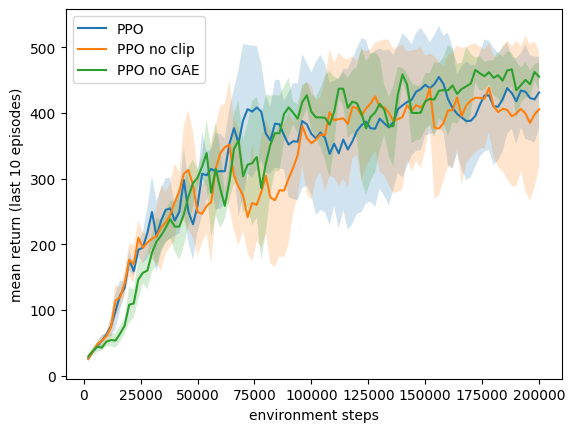

In [8]:
all_runs = {"PPO": run_seeds()}
# TODO: train the two changed versions
no_clip_config = {"clip_coef": 1e9}
all_runs["PPO no clip"] = run_seeds(cfg=no_clip_config)

# PPO without GAE (Monte Carlo advantages)
no_gae_config = {"gae_lambda": 1.0}
all_runs["PPO no GAE"] = run_seeds(cfg=no_gae_config)

results = {name: summarize(runs, name) for name, runs in all_runs.items()}
plot_curves(all_runs)

In [9]:
train_ppo(0, verbose=True)

step  10240  mean return (last 10)   59.0  clip frac 0.000
step  20480  mean return (last 10)  150.5  clip frac 0.000
step  30720  mean return (last 10)  162.2  clip frac 0.000
step  40960  mean return (last 10)  252.1  clip frac 0.000
step  51200  mean return (last 10)  239.1  clip frac 0.000
step  61440  mean return (last 10)  277.1  clip frac 0.001
step  71680  mean return (last 10)  468.2  clip frac 0.000
step  81920  mean return (last 10)  453.0  clip frac 0.000
step  92160  mean return (last 10)  474.3  clip frac 0.000
step 102400  mean return (last 10)  484.4  clip frac 0.000
step 112640  mean return (last 10)  470.1  clip frac 0.000
step 122880  mean return (last 10)  482.3  clip frac 0.001
step 133120  mean return (last 10)  500.0  clip frac 0.000
step 143360  mean return (last 10)  477.4  clip frac 0.000
step 153600  mean return (last 10)  481.4  clip frac 0.000
step 163840  mean return (last 10)  459.9  clip frac 0.000
step 174080  mean return (last 10)  478.6  clip frac 0.0

(Agent(
   (critic): Sequential(
     (0): Linear(in_features=4, out_features=64, bias=True)
     (1): Tanh()
     (2): Linear(in_features=64, out_features=64, bias=True)
     (3): Tanh()
     (4): Linear(in_features=64, out_features=1, bias=True)
   )
   (actor): Sequential(
     (0): Linear(in_features=4, out_features=64, bias=True)
     (1): Tanh()
     (2): Linear(in_features=64, out_features=64, bias=True)
     (3): Tanh()
     (4): Linear(in_features=64, out_features=2, bias=True)
   )
 ),
 [(47, np.float64(12.0)),
  (60, np.float64(15.0)),
  (69, np.float64(18.0)),
  (98, np.float64(25.0)),
  (119, np.float64(18.0)),
  (134, np.float64(9.0)),
  (137, np.float64(17.0)),
  (140, np.float64(20.0)),
  (217, np.float64(20.0)),
  (219, np.float64(25.0)),
  (226, np.float64(23.0)),
  (265, np.float64(12.0)),
  (270, np.float64(11.0)),
  (288, np.float64(37.0)),
  (305, np.float64(10.0)),
  (311, np.float64(23.0)),
  (314, np.float64(11.0)),
  (349, np.float64(11.0)),
  (400, np.float64

In [10]:
def collect_rollout(agent, seed, N=8, T=500):
    envs = Envs(N, seed)
    rewards = torch.zeros(T, N); dones = torch.zeros(T, N); values = torch.zeros(T, N)
    next_obs = torch.tensor(envs.obs, dtype=torch.float32); next_done = torch.zeros(N)
    for t in range(T):
        dones[t] = next_done
        with torch.no_grad():
            a, _, _, v = agent.get_action_and_value(next_obs)
        values[t] = v
        o, r, term, trunc, _ = envs.step(a.numpy())
        rewards[t] = torch.tensor(r, dtype=torch.float32)
        next_obs = torch.tensor(o, dtype=torch.float32)
        next_done = torch.tensor(term | trunc, dtype=torch.float32)
    with torch.no_grad():
        nv = agent.get_value(next_obs)
    return rewards, values, dones, nv, next_done

# a partly trained agent, so that the critic is imperfect
agent_mid, _, _ = train_ppo(0, {"total_steps": 60_000})
lams = [0.0, 0.5, 0.9, 0.95, 1.0]
stds = {l: [] for l in lams}; diffs = {l: [] for l in lams}
for s in range(5):
    rewards, values, dones, nv, nd = collect_rollout(agent_mid, seed=1000 + s)
    advs = {l: compute_gae(rewards, values, dones, nv, nd, CONFIG["gamma"], l)[0] for l in lams}
    for l in lams:
        stds[l].append(advs[l].std().item())
        diffs[l].append((advs[l] - advs[1.0]).abs().mean().item())   # lambda = 1 is the (nearly) unbiased Monte Carlo estimate
print("lambda   std of advantages   mean |A_lambda - A_1|  (proxy for the bias of A_lambda)")
for l in lams:
    print(f"{l:5.2f}   {np.mean(stds[l]):12.2f}   {np.mean(diffs[l]):14.2f}")

lambda   std of advantages   mean |A_lambda - A_1|  (proxy for the bias of A_lambda)
 0.00           1.37            40.41
 0.50           1.62            39.74
 0.90           3.68            34.93
 0.95           5.70            30.18
 1.00          24.68             0.00


PPO            runs that reach 475: 5/5   fraction of later points still >= 475: 0.31   mean worst later point: 291.6
PPO no clip    runs that reach 475: 5/5   fraction of later points still >= 475: 0.31   mean worst later point: 228.2
PPO no GAE     runs that reach 475: 4/5   fraction of later points still >= 475: 0.30   mean worst later point: 372.4


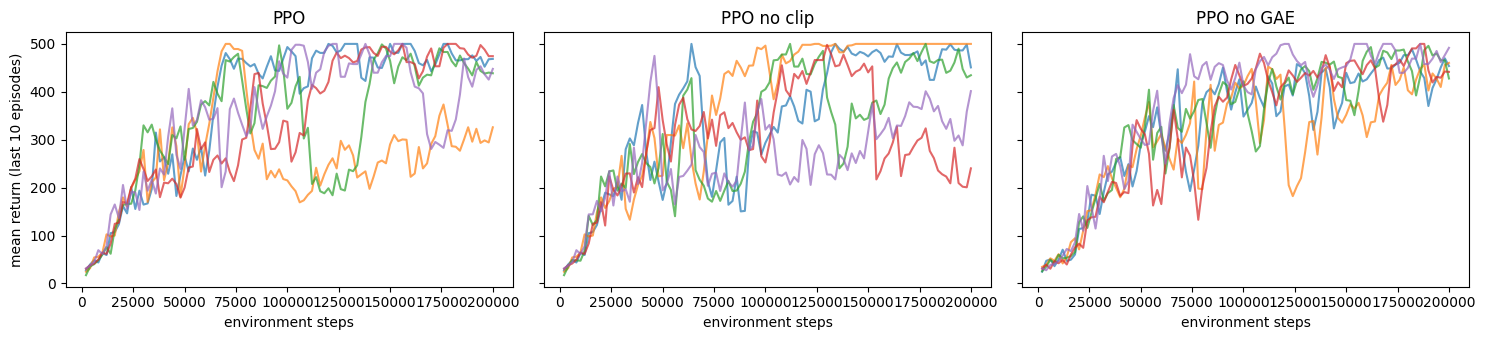

In [11]:
import matplotlib.pyplot as plt

def stability(runs, target=475):
    kept, worst, reached = [], [], 0
    for r in runs:
        c = learning_curve(r["episodes"])[1]
        hit = np.where(c >= target)[0]
        if len(hit) == 0:
            continue
        reached += 1
        after = c[hit[0]:]
        kept.append((after >= target).mean())   # fraction of later points still >= target
        worst.append(after.min())               # worst later point
    return reached, (np.mean(kept) if kept else float("nan")), (np.mean(worst) if worst else float("nan"))

for name, runs in all_runs.items():
    reached, kept, worst = stability(runs)
    print(f"{name:<14} runs that reach 475: {reached}/5   fraction of later points still >= 475: {kept:.2f}   mean worst later point: {worst:.1f}")

fig, axes = plt.subplots(1, len(all_runs), figsize=(5 * len(all_runs), 3.5), sharey=True)
for ax, (name, runs) in zip(axes, all_runs.items()):
    for r in runs:
        g, c = learning_curve(r["episodes"])
        ax.plot(g, c, alpha=0.7)
    ax.set_title(name); ax.set_xlabel("environment steps")
axes[0].set_ylabel("mean return (last 10 episodes)")
plt.tight_layout(); plt.show()

# Bonus Research Question 2: your method

Write your method as a copy of `train_ppo` (and of the other functions that you change).
Use `run_seeds(train_fn=my_train_ppo)` and `summarize` for the results.

In [12]:
def grad_norm_of(parameters):
    total = 0.0
    for p in parameters:
        if p.grad is not None:
            total = total + p.grad.detach().pow(2).sum().item()
    return total ** 0.5


def my_ppo_update(agent, opt, b, cfg):
    n = len(b["obs"])
    mb_size = n // cfg["num_minibatches"]

    clip_fracs = []
    actor_norms = []
    critic_norms = []
    value_losses = []

    for _ in range(cfg["update_epochs"]):
        idx = torch.randperm(n)
        for start in range(0, n, mb_size):
            mb = idx[start:start + mb_size]
            _, logp, ent, v = agent.get_action_and_value(b["obs"][mb], b["actions"][mb])
            ratio = (logp - b["logp"][mb]).exp()

            adv = b["adv"][mb]
            if cfg["norm_adv"]:
                adv = (adv - adv.mean()) / (adv.std() + 1e-8)

            pg_loss = torch.max(
                -adv * ratio,
                -adv * ratio.clamp(1 - cfg["clip_coef"], 1 + cfg["clip_coef"])).mean()
            v_loss = 0.5 * ((v - b["returns"][mb]) ** 2).mean()
            loss = pg_loss - cfg["ent_coef"] * ent.mean() + cfg["vf_coef"] * v_loss

            opt.zero_grad()
            loss.backward()

            # gradient norms before clipping (evidence for the analysis)
            actor_norm = grad_norm_of(agent.actor.parameters())
            critic_norm = grad_norm_of(agent.critic.parameters())

            if cfg.get("split_clip", False):
                # Part B: clip actor and critic separately
                nn.utils.clip_grad_norm_(agent.actor.parameters(), cfg["max_grad_norm"])
                nn.utils.clip_grad_norm_(agent.critic.parameters(), cfg["max_grad_norm"])
            else:
                nn.utils.clip_grad_norm_(agent.parameters(), cfg["max_grad_norm"])
            opt.step()

            clip_fracs.append(((ratio - 1).abs() > cfg["clip_coef"]).float().mean().item())
            actor_norms.append(actor_norm)
            critic_norms.append(critic_norm)
            value_losses.append(v_loss.item())

    stats = {}
    stats["clip_frac"] = float(np.mean(clip_fracs))
    stats["actor_grad_norm"] = float(np.mean(actor_norms))
    stats["critic_grad_norm"] = float(np.mean(critic_norms))
    stats["value_loss"] = float(np.mean(value_losses))
    return stats


DIAGNOSTICS = {}   # (tag, seed) -> list of per-update statistics


def my_train_ppo(seed, cfg=None, verbose=False, options=None):
    cfg = {**CONFIG, **(cfg or {})}
    tag = cfg.get("tag", "mine")
    use_bootstrap = cfg.get("bootstrap_trunc", True)

    torch.manual_seed(seed)
    np.random.seed(seed)
    envs = Envs(cfg["num_envs"], seed)
    agent = Agent()
    opt = torch.optim.Adam(agent.parameters(), lr=cfg["lr"], eps=1e-5)

    N, T = cfg["num_envs"], cfg["num_steps"]
    n_updates = cfg["total_steps"] // (N * T)
    obs = torch.zeros(T, N, 4)
    actions = torch.zeros(T, N, dtype=torch.long)
    logps = torch.zeros(T, N)
    rewards = torch.zeros(T, N)
    dones = torch.zeros(T, N)
    values = torch.zeros(T, N)
    next_obs = torch.tensor(envs.obs, dtype=torch.float32)
    next_done = torch.zeros(N)

    DIAGNOSTICS[(tag, seed)] = []
    start = time.time()

    for update in range(n_updates):
        if cfg["anneal_lr"]:
            opt.param_groups[0]["lr"] = cfg["lr"] * (1 - update / n_updates)

        for t in range(T):
            obs[t], dones[t] = next_obs, next_done
            with torch.no_grad():
                a, logp, _, v = agent.get_action_and_value(next_obs)
            actions[t], logps[t], values[t] = a, logp, v

            o, r, term, trunc, final_obs = envs.step(a.numpy())
            reward_t = torch.tensor(r, dtype=torch.float32)

            if use_bootstrap:
                # Part A: if the episode ended only because of the time limit,
                # add gamma * V(final state) to the reward of that step.
                for i in range(N):
                    ended_by_time_limit = bool(trunc[i]) and (not bool(term[i]))
                    if ended_by_time_limit:
                        final_state = torch.tensor(final_obs[i], dtype=torch.float32)
                        with torch.no_grad():
                            final_value = agent.get_value(final_state)
                        reward_t[i] = reward_t[i] + cfg["gamma"] * final_value

            rewards[t] = reward_t
            next_obs = torch.tensor(o, dtype=torch.float32)
            next_done = torch.tensor(term | trunc, dtype=torch.float32)

        with torch.no_grad():
            adv, returns = compute_gae(rewards, values, dones, agent.get_value(next_obs), next_done,
                                       cfg["gamma"], cfg["gae_lambda"])
        b = {
            "obs": obs.reshape(-1, 4),
            "actions": actions.reshape(-1),
            "logp": logps.reshape(-1),
            "adv": adv.reshape(-1),
            "returns": returns.reshape(-1),
        }
        stats = my_ppo_update(agent, opt, b, cfg)
        stats["update"] = update
        stats["global_step"] = envs.global_step
        DIAGNOSTICS[(tag, seed)].append(stats)

        if verbose and (update + 1) % 20 == 0:
            recent = []
            for _, ret in envs.episodes[-10:]:
                recent.append(ret)
            print(f"step {envs.global_step:6d}  mean return (last 10) {np.mean(recent):6.1f}  "
                  f"actor grad {stats['actor_grad_norm']:.3f}  critic grad {stats['critic_grad_norm']:.3f}")

    return agent, envs.episodes, time.time() - start

In [13]:
check_cfg = {"bootstrap_trunc": False, "split_clip": False, "tag": "check"}
check_runs = run_seeds(cfg=check_cfg, seeds=[0], train_fn=my_train_ppo)
print("Original PPO, seed 0 final:", all_runs["PPO"][0]["final"],
      "| my code with both parts off:", check_runs[0]["final"])

seed 0: auc  377.2  steps_to_475  69959  final  500.0  time  43.1 s
Original PPO, seed 0 final: 500.0 | my code with both parts off: 500.0


seed 0: auc  392.3  steps_to_475  92564  final  500.0  time  44.4 s
seed 1: auc  367.5  steps_to_475  92607  final  500.0  time  44.3 s
seed 2: auc  338.4  steps_to_475 157447  final  500.0  time  44.4 s
seed 3: auc  364.0  steps_to_475  46509  final  500.0  time  44.1 s
seed 4: auc  303.1  steps_to_475 135097  final  500.0  time  44.0 s
seed 0: auc  358.0  steps_to_475 103053  final  480.6  time  42.9 s
seed 1: auc  352.9  steps_to_475 104943  final  500.0  time  43.1 s
seed 2: auc  384.1  steps_to_475  66443  final  500.0  time  43.5 s
seed 3: auc  334.7  steps_to_475  89474  final  500.0  time  43.4 s
seed 4: auc  308.7  steps_to_475  85906  final  402.6  time  42.9 s
seed 0: auc  398.1  steps_to_475  74231  final  500.0  time  43.6 s
seed 1: auc  313.3  steps_to_475  81889  final  493.0  time  43.8 s
seed 2: auc  371.9  steps_to_475  89075  final  500.0  time  44.0 s
seed 3: auc  329.4  steps_to_475 139142  final  466.3  time  44.7 s
seed 4: auc  393.7  steps_to_475  53987  final  

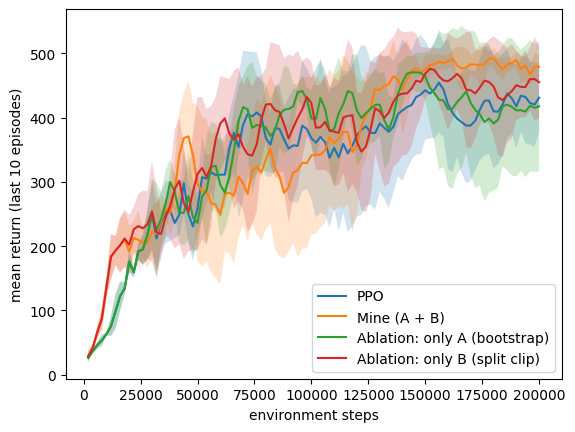

In [14]:
bonus_runs = {}
bonus_runs["PPO"] = all_runs["PPO"]

mine_cfg = {"bootstrap_trunc": True, "split_clip": True, "tag": "mine"}
bonus_runs["Mine (A + B)"] = run_seeds(cfg=mine_cfg, train_fn=my_train_ppo)

only_a_cfg = {"bootstrap_trunc": True, "split_clip": False, "tag": "only_A"}
bonus_runs["Ablation: only A (bootstrap)"] = run_seeds(cfg=only_a_cfg, train_fn=my_train_ppo)

only_b_cfg = {"bootstrap_trunc": False, "split_clip": True, "tag": "only_B"}
bonus_runs["Ablation: only B (split clip)"] = run_seeds(cfg=only_b_cfg, train_fn=my_train_ppo)

bonus_results = {}
for name, runs in bonus_runs.items():
    bonus_results[name] = summarize(runs, name)

plot_curves(bonus_runs)

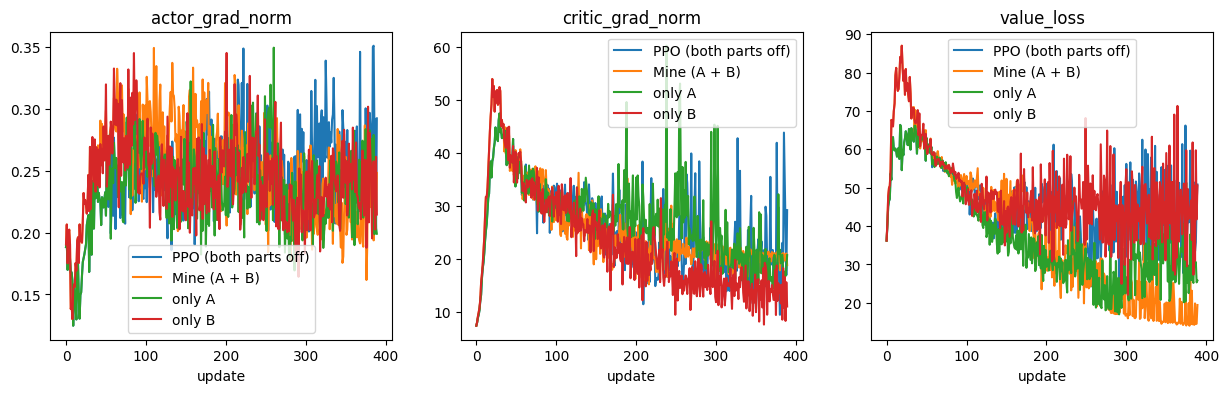

In [15]:
import matplotlib.pyplot as plt

def mean_diagnostic(tag, key):
    curves = []
    for seed in SEEDS:
        series = []
        for stats in DIAGNOSTICS[(tag, seed)]:
            series.append(stats[key])
        curves.append(series)
    return np.mean(np.array(curves), axis=0)

# PPO with both parts off, all 5 seeds, to compare diagnostics
check_runs_all = run_seeds(cfg=check_cfg, train_fn=my_train_ppo, verbose=False)

tags_to_plot = {"check": "PPO (both parts off)", "mine": "Mine (A + B)",
                "only_A": "only A", "only_B": "only B"}
figure, axes = plt.subplots(1, 3, figsize=(15, 4))
keys = ["actor_grad_norm", "critic_grad_norm", "value_loss"]
for axis, key in zip(axes, keys):
    for tag, label in tags_to_plot.items():
        axis.plot(mean_diagnostic(tag, key), label=label)
    axis.set_title(key)
    axis.set_xlabel("update")
    axis.legend()
plt.show()